## Carbon System Analysis

In [1]:
import xarray as xr
import gsw
import PyCO2SYS as pyco2
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
from cmocean import cm
from salishsea_tools import visualisations as vis
import netCDF4 as nc
from matplotlib.colors import ListedColormap

In [2]:
# other grid files for thalweg plots
mesh = nc.Dataset('/home/sallen/MEOPAR/grid/mesh_mask201702.nc')
bathy = nc.Dataset("/home/sallen/MEOPAR/grid/bathymetry_202108.nc", mask_and_scale=False)
thalweg_in = '/home/sallen/MEOPAR/Tools/bathymetry/thalweg_working.txt'

## 5 year mean

In [4]:
# load data

base = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/arag_basecase_5yr.nc")
all = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/arag_allcase_5yr.nc")


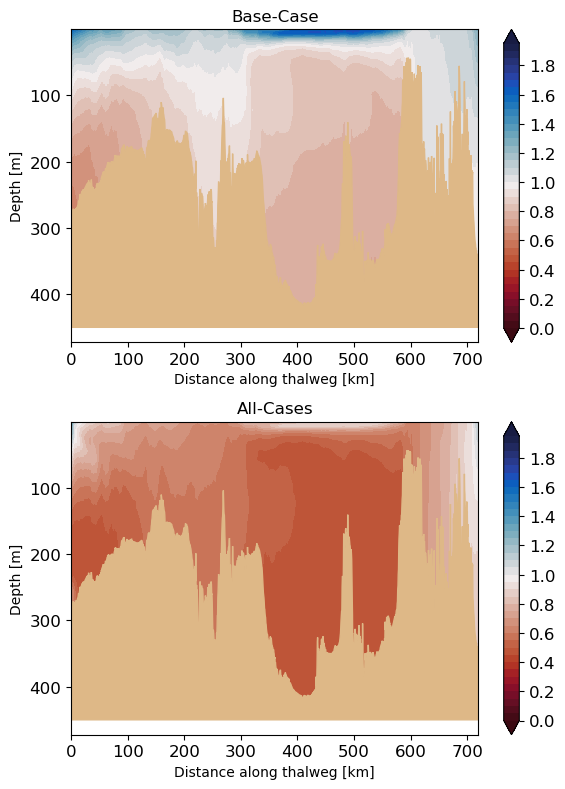

In [6]:
arag_range = np.arange(0,2,0.05)

fig, ax = plt.subplots(2,1,figsize=[6,8])

cbar = vis.contour_thalweg(ax[0], base.saturation_aragonite.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0].tick_params(axis='both', which='major', labelsize=12)
ax[0].set_title('Base-Case')

cbar = vis.contour_thalweg(ax[1], all.saturation_aragonite.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1].tick_params(axis='both', which='major', labelsize=12)
ax[1].set_title('All-Cases')

plt.tight_layout()

## seasonal
plus compare to tereza results

In [21]:
allwinter = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/arag_allcase_winter.nc")
allsummer = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/arag_allcase_summer.nc")
basewinter = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/arag_basecase_winter.nc")
basesummer = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/arag_basecase_summer.nc")
salishwinter = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/arag_salishcase_winter.nc")
salishsummer = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/arag_salishcase_summer.nc")

In [4]:
path = Path("/data/tjarniko/results/BASERUN_EXP/Oma_calc/")

date_list = list(pd.date_range('2015-01-01','2015-02-28')) + list(pd.date_range('2015-12-01','2015-12-31'))
files = [path/f"PI9_OmA_plus_{date:%Y%m%d}.nc" for date in date_list]
piwinter = xr.open_mfdataset(files, group='model_output', engine="netcdf4", combine='nested', concat_dim='time').mean('time')

date_list = list(pd.date_range('2015-06-01','2015-08-31'))
files = [path/f"PI9_OmA_plus_{date:%Y%m%d}.nc" for date in date_list]
pisummer = xr.open_mfdataset(files, group='model_output', engine="netcdf4", combine='nested', concat_dim='time').mean('time')

In [5]:
# Black band with transparent values outside the contour levels
line_cmap = ListedColormap(['black'])
line_cmap.set_under((0, 0, 0, 0))
line_cmap.set_over((0, 0, 0, 0))

/tmp/ipykernel_2135701/2526030425.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


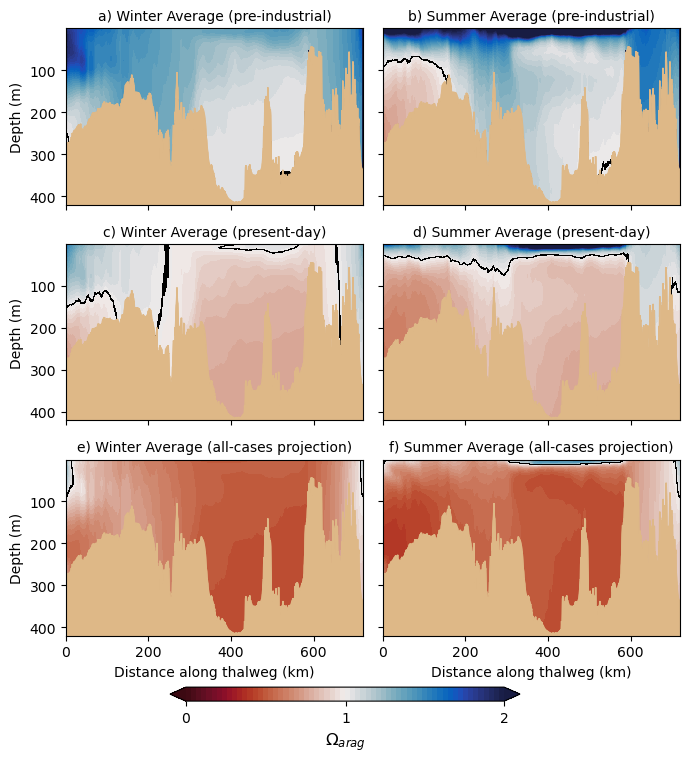

In [6]:
arag_range = np.arange(0,2,0.032)

fig, ax = plt.subplots(3,2,figsize=[7,7])

# pre-industrial (top row)
cbar = vis.contour_thalweg(ax[0,0], piwinter.OmA.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
cbar.remove()
cline = vis.contour_thalweg(ax[0,0], piwinter.OmA.values, bathy, mesh, clevels=[0.999,1.001], cmap=line_cmap, thalweg_file=thalweg_in)
cline.remove()
ax[0,0].set_title('a) Winter Average (pre-industrial)',fontsize=10)

cbar = vis.contour_thalweg(ax[0,1], pisummer.OmA.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
cbar.remove()
cline = vis.contour_thalweg(ax[0,1], pisummer.OmA.values, bathy, mesh, clevels=[0.999,1.001], cmap=line_cmap, thalweg_file=thalweg_in)
cline.remove()
ax[0,1].set_title('b) Summer Average (pre-industrial)',fontsize=10)

# present-day (middle row)
cbar = vis.contour_thalweg(ax[1,0], basewinter.saturation_aragonite.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
cbar.remove()
cline = vis.contour_thalweg(ax[1,0], basewinter.saturation_aragonite.values, bathy, mesh, clevels=[0.999,1.001], cmap=line_cmap, thalweg_file=thalweg_in)
cline.remove()
ax[1,0].set_title('c) Winter Average (present-day)',fontsize=10)

cbar = vis.contour_thalweg(ax[1,1], basesummer.saturation_aragonite.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
cbar.remove()
cline = vis.contour_thalweg(ax[1,1], basesummer.saturation_aragonite.values, bathy, mesh, clevels=[0.999,1.001], cmap=line_cmap, thalweg_file=thalweg_in)
cline.remove()
ax[1,1].set_title('d) Summer Average (present-day)',fontsize=10)

# projection (bottom row)
cbar = vis.contour_thalweg(ax[2,0], allwinter.saturation_aragonite.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
cbar.remove()
cline = vis.contour_thalweg(ax[2,0], allwinter.saturation_aragonite.values, bathy, mesh, clevels=[0.999,1.001], cmap=line_cmap, thalweg_file=thalweg_in)
cline.remove()
ax[2,0].set_title('e) Winter Average (all-cases projection)',fontsize=10)

cbar = vis.contour_thalweg(ax[2,1], allsummer.saturation_aragonite.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
cbar.remove()
cline = vis.contour_thalweg(ax[2,1], allsummer.saturation_aragonite.values, bathy, mesh, clevels=[0.999,1.001], cmap=line_cmap, thalweg_file=thalweg_in)
cline.remove()
ax[2,1].set_title('f) Summer Average (all-cases projection)',fontsize=10)

cax = fig.add_axes([0.25, -0.01, 0.5, 0.02])
cb = fig.colorbar(cbar.mappable, cax=cax, orientation='horizontal',ticks=[0,1,2])
cb.set_label(r'$\Omega_{arag}$', fontsize = 12)

# formatting
for i in range(3):
    for j in range(2):
        ax[i,j].set_ylim([420,0])
        ax[i,j].set_xticks([0,200,400,600])
        ax[i,j].set_xticklabels([])
        ax[i,j].set_xlabel('')
        ax[i,j].set_yticks([100,200,300,400])
        ax[i,j].set_yticklabels([])
        ax[i,j].set_ylabel('')
for i in range(3):
    ax[i,0].set_yticklabels([100,200,300,400])
    ax[i,0].set_ylabel('Depth (m)')
for j in range(2):
    ax[2,j].set_xticklabels([0,200,400,600])
    ax[2,j].set_xlabel('Distance along thalweg (km)')

plt.tight_layout()

/tmp/ipykernel_2135701/3233493110.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


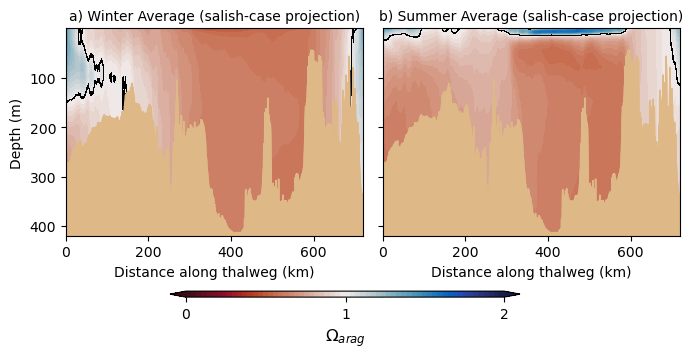

In [22]:
arag_range = np.arange(0,2,0.032)

fig, ax = plt.subplots(1,2,figsize=[7,3])

# projection (bottom row)
cbar = vis.contour_thalweg(ax[0], salishwinter.saturation_aragonite.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
cbar.remove()
cline = vis.contour_thalweg(ax[0], salishwinter.saturation_aragonite.values, bathy, mesh, clevels=[0.999,1.001], cmap=line_cmap, thalweg_file=thalweg_in)
cline.remove()
ax[0].set_title('a) Winter Average (salish-case projection)',fontsize=10)

cbar = vis.contour_thalweg(ax[1], salishsummer.saturation_aragonite.values, bathy, mesh, clevels=arag_range, cmap = cm.balance_r, thalweg_file=thalweg_in)
cbar.remove()
cline = vis.contour_thalweg(ax[1], salishsummer.saturation_aragonite.values, bathy, mesh, clevels=[0.999,1.001], cmap=line_cmap, thalweg_file=thalweg_in)
cline.remove()
ax[1].set_title('b) Summer Average (salish-case projection)',fontsize=10)

cax = fig.add_axes([0.25, -0.01, 0.5, 0.02])
cb = fig.colorbar(cbar.mappable, cax=cax, orientation='horizontal',ticks=[0,1,2])
cb.set_label(r'$\Omega_{arag}$', fontsize = 12)

# formatting
for axs in ax:
    axs.set_ylim([420,0])
    axs.set_xticks([0,200,400,600])
    axs.set_xlabel('Distance along thalweg (km)')
    axs.set_yticks([100,200,300,400])
ax[1].set_yticklabels([])
ax[1].set_ylabel('')
ax[0].set_yticklabels([100,200,300,400])
ax[0].set_ylabel('Depth (m)')


plt.tight_layout()

In [7]:
grid = xr.open_dataset('/home/sallen/MEOPAR/grid/mesh_mask201702.nc')
_, _, w = np.meshgrid(grid.x,grid.y,grid.e3t_1d.values,)
u = np.repeat(grid.e1t.values[0,:,:,np.newaxis],40,axis=2)
v = np.repeat(grid.e2t.values[0,:,:,np.newaxis],40,axis=2)

volume = u*v*w
volume = volume.reshape((40,898,398))
# mask according to the grid
volume = np.where(grid.tmask[0,...].values==1,volume,np.nan)
totalvol = np.nansum(volume)

In [8]:
# pre-industrial percentage of volumes
for i in [0.5,0.7,1.0,1.3,1.5]:
    print(f"fraction of model domain below {i} in the summer = {np.round(1-np.nansum(np.where(pisummer.OmA.values>=i,volume,np.nan))/totalvol,2)}")

print('\n')
for i in [0.5,0.7,1.0,1.3,1.5]:
    print(f"fraction of model domain below {i} in the winter = {np.round(1-np.nansum(np.where(piwinter.OmA.values>=i,volume,np.nan))/totalvol,2)}")

fraction of model domain below 0.5 in the summer = 0.0
fraction of model domain below 0.7 in the summer = 0.0
fraction of model domain below 1.0 in the summer = 0.05
fraction of model domain below 1.3 in the summer = 0.19
fraction of model domain below 1.5 in the summer = 0.25


fraction of model domain below 0.5 in the winter = 0.0
fraction of model domain below 0.7 in the winter = 0.0
fraction of model domain below 1.0 in the winter = 0.03
fraction of model domain below 1.3 in the winter = 0.26
fraction of model domain below 1.5 in the winter = 0.84


In [9]:
# present percentage of volumes
for i in [0.5,0.7,1.0,1.3,1.5]:
    print(f"fraction of model domain below {i} in the summer = {np.round(1-np.nansum(np.where(basesummer.saturation_aragonite.values>=i,volume,np.nan))/totalvol,2)}")

print('\n')
for i in [0.5,0.7,1.0,1.3,1.5]:
    print(f"fraction of model domain below {i} in the winter = {np.round(1-np.nansum(np.where(basewinter.saturation_aragonite.values>=i,volume,np.nan))/totalvol,2)}")

fraction of model domain below 0.5 in the summer = 0.01
fraction of model domain below 0.7 in the summer = 0.04
fraction of model domain below 1.0 in the summer = 0.22
fraction of model domain below 1.3 in the summer = 0.56
fraction of model domain below 1.5 in the summer = 0.7


fraction of model domain below 0.5 in the winter = 0.01
fraction of model domain below 0.7 in the winter = 0.02
fraction of model domain below 1.0 in the winter = 0.52
fraction of model domain below 1.3 in the winter = 0.98
fraction of model domain below 1.5 in the winter = 1.0


In [10]:
# projected percentage of volumes
for i in [0.5,0.7,1.0,1.3,1.5]:
    print(f"fraction of model domain below {i} in the summer = {np.round(1-np.nansum(np.where(allsummer.saturation_aragonite.values>=i,volume,np.nan))/totalvol,2)}")

print('\n')
for i in [0.5,0.7,1.0,1.3,1.5]:
    print(f"fraction of model domain below {i} in the winter = {np.round(1-np.nansum(np.where(allwinter.saturation_aragonite.values>=i,volume,np.nan))/totalvol,2)}")

fraction of model domain below 0.5 in the summer = 0.14
fraction of model domain below 0.7 in the summer = 0.41
fraction of model domain below 1.0 in the summer = 0.78
fraction of model domain below 1.3 in the summer = 0.92
fraction of model domain below 1.5 in the summer = 0.97


fraction of model domain below 0.5 in the winter = 0.24
fraction of model domain below 0.7 in the winter = 0.86
fraction of model domain below 1.0 in the winter = 0.98
fraction of model domain below 1.3 in the winter = 1.0
fraction of model domain below 1.5 in the winter = 1.0


In [23]:
# projected percentage of volumes in the salish case
for i in [0.5,0.7,1.0,1.3,1.5]:
    print(f"fraction of model domain below {i} in the summer = {np.round(1-np.nansum(np.where(salishsummer.saturation_aragonite.values>=i,volume,np.nan))/totalvol,2)}")

print('\n')
for i in [0.5,0.7,1.0,1.3,1.5]:
    print(f"fraction of model domain below {i} in the winter = {np.round(1-np.nansum(np.where(salishwinter.saturation_aragonite.values>=i,volume,np.nan))/totalvol,2)}")

fraction of model domain below 0.5 in the summer = 0.02
fraction of model domain below 0.7 in the summer = 0.19
fraction of model domain below 1.0 in the summer = 0.6
fraction of model domain below 1.3 in the summer = 0.83
fraction of model domain below 1.5 in the summer = 0.93


fraction of model domain below 0.5 in the winter = 0.07
fraction of model domain below 0.7 in the winter = 0.68
fraction of model domain below 1.0 in the winter = 0.96
fraction of model domain below 1.3 in the winter = 0.99
fraction of model domain below 1.5 in the winter = 1.0


## mean changes by box

In [76]:
# load data

# base case (202111)
basecsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/csg202111.nc')
basejdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/jdf202111.nc')
basensg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/nsg202111.nc')
basepug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/pug202111.nc')

# all scenario
allcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/All_cgs.nc')
alljdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/All_jdf.nc')
allnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/All_nsg.nc')
allpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/All_pug.nc')

# local scenario
localcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Local_cgs.nc')
localjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Local_jdf.nc')
localnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Local_nsg.nc')
localpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Local_pug.nc')

# northwest scenario
northcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/NorthWest_cgs.nc')
northjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/NorthWest_jdf.nc')
northnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/NorthWest_nsg.nc')
northpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/NorthWest_pug.nc')

# salish scenario
salishcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Salish_cgs.nc')
salishjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Salish_jdf.nc')
salishnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Salish_nsg.nc')
salishpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Salish_pug.nc')

# south scenario
southcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/South_cgs.nc')
southjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/South_jdf.nc')
southnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/South_nsg.nc')
southpug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/South_pug.nc')

# upwelling scenario
upcsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Up_cgs.nc')
upjdf = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Up_jdf.nc')
upnsg = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Up_nsg.nc')
uppug = xr.open_dataset('/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/Up_pug.nc')

In [77]:
colours = ['#CCBB44','#AA3377','#228833','#4477AA','#66CCEE','#EE6677']
scenarios = ['All','Salish','Local','North','Up','South']

def theoretical(regionlist):
    theo = regionlist[1]+(regionlist[2]-regionlist[1])+(regionlist[3]-regionlist[1])+(regionlist[4]-regionlist[1])+(regionlist[5]-regionlist[1])
    return theo

In [98]:
def mean_arag(data,ind):
    dat = data.mean('month')
    dep = dat.depth[ind]

    # convert to correct units
    SP = gsw.conversions.SP_from_SR(dat.vosaline[ind].values)
    SA = gsw.conversions.SA_from_SP(SP,dep,-123,49)
    rho = gsw.density.rho(SA,dat.votemper[ind].values,dep)
    TA = dat.total_alkalinity[ind].values * (1/rho) * 1000 # convert from mmol/m3 to umol/kg
    DIC = dat.dissolved_inorganic_carbon[ind].values * (1/rho) * 1000 # convert from mmol/m3 to umol/kg
    Temp = gsw.conversions.t_from_CT(SA,dat.votemper[ind].values,dep)

    co2sys = pyco2.sys(
        par1=TA,          # TA [µmol/kg]
        par2=DIC,          # DIC [µmol/kg]
        par1_type=1,        # Total alkalinity
        par2_type=2,        # Dissolved inorganic carbon
        salinity=SP,      # Practical salinity
        temperature=Temp,    # In situ temperature [°C]
        pressure=dep,       # Seawater pressure [dbar]
        opt_k_carbonic=10,  # Lueker et al. (2000)
        opt_buffers_mode=0,
    )

    return co2sys["saturation_aragonite"]
    

In [99]:
mean_arag(allcsg,23)

np.float64(0.48923420087568353)

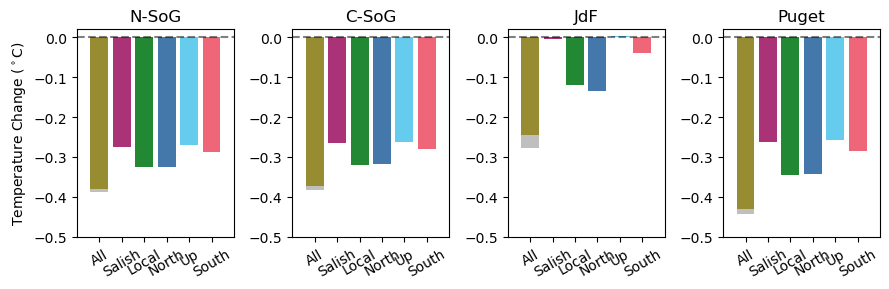

In [102]:
# seasonal change at 100 m

fig, ax = plt.subplots(1,4,figsize=[9,3])

nsgchange = [mean_arag(allnsg,23)-mean_arag(basensg,23),
             mean_arag(salishnsg,23)-mean_arag(basensg,23),
             mean_arag(localnsg,23)-mean_arag(basensg,23),
             mean_arag(northnsg,23)-mean_arag(basensg,23),
             mean_arag(upnsg,23)-mean_arag(basensg,23),
             mean_arag(southnsg,23)-mean_arag(basensg,23)] # need to add all and up later

csgchange = [mean_arag(allcsg,23)-mean_arag(basecsg,23),
             mean_arag(salishcsg,23)-mean_arag(basecsg,23),
             mean_arag(localcsg,23)-mean_arag(basecsg,23),
             mean_arag(northcsg,23)-mean_arag(basecsg,23),
             mean_arag(upcsg,23)-mean_arag(basecsg,23),
             mean_arag(southcsg,23)-mean_arag(basecsg,23)]

jdfchange = [mean_arag(alljdf,28)-mean_arag(basejdf,28),
             mean_arag(salishjdf,28)-mean_arag(basejdf,28),
             mean_arag(localjdf,28)-mean_arag(basejdf,28),
             mean_arag(northjdf,28)-mean_arag(basejdf,28),
             mean_arag(upjdf,28)-mean_arag(basejdf,28),
             mean_arag(southjdf,28)-mean_arag(basejdf,28)]

pugchange = [mean_arag(allpug,23)-mean_arag(basepug,23),
             mean_arag(salishpug,23)-mean_arag(basepug,23),
             mean_arag(localpug,23)-mean_arag(basepug,23),
             mean_arag(northpug,23)-mean_arag(basepug,23),
             mean_arag(uppug,23)-mean_arag(basepug,23),
             mean_arag(southpug,23)-mean_arag(basepug,23)]

ax[0].bar(scenarios,nsgchange,color=colours)
ax[1].bar(scenarios,csgchange,color=colours)
ax[2].bar(scenarios,jdfchange,color=colours)
ax[3].bar(scenarios,pugchange,color=colours)

# add "theoretical linear change" to the all location
ax[0].bar(scenarios[0],theoretical(nsgchange),color='k',alpha=0.25)
ax[1].bar(scenarios[0],theoretical(csgchange),color='k',alpha=0.25)
ax[2].bar(scenarios[0],theoretical(jdfchange),color='k',alpha=0.25)
ax[3].bar(scenarios[0],theoretical(pugchange),color='k',alpha=0.25)

# formatting
for axx in ax:
    axx.set_ylim([-0.5,0.02])
    axx.set_xlim([-1,len(scenarios)])
    axx.set_xticks(np.arange(len(scenarios)))
    axx.set_xticklabels(scenarios,rotation=30)
    axx.hlines(xmin=-1,xmax=len(scenarios),y=-0,colors='k',linestyles='dashed',alpha=0.5)

ax[0].set_ylabel(r'Temperature Change ($^\circ$C)')
ax[0].set_title('N-SoG')
ax[1].set_title('C-SoG')
ax[2].set_title('JdF')
ax[3].set_title('Puget')


plt.tight_layout()